<a href="https://colab.research.google.com/github/Atin2001/GCI/blob/main/GCI2026W_%E7%AC%AC6%E5%9B%9E_%E6%95%99%E5%B8%AB%E3%81%82%E3%82%8A%E5%AD%A6%E7%BF%92_ipynb_%E3%81%AE%E3%82%B3%E3%83%94%E3%83%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第6回 機械学習の基礎（教師あり学習）

第6回からは、機械学習について学びます。機械学習とは、データから規則性やパターンを学び、予測や意思決定などに役立てる技術です。機械学習は大きく、教師あり学習、教師なし学習、強化学習に分けられ、第6回では、教師あり学習の具体的手法について学びます。本ノートブックを通して、機械学習の考え方とモデル構築・評価の基本的な進め方を身につけましょう。


ゴール：機械学習の体系と概要を学び、モデル構築や評価を正しく実行できるようになる

> **このNotebookについて**
>
> この回では、教師あり学習の基本的な考え方と、モデル構築・評価の基本作法を学びます。  
> 本編では **重回帰・ロジスティック回帰・正則化の考え方・決定木** を扱います。  
> **k-NN（k近傍法）とSVM（サポートベクターマシン）などのアルゴリズムは発展・自習項目**とし、必要になったときに公式ドキュメント等を調べてください。

### 用語の補足

本ノートブックでは、次の用語を区別して使います。

- **目的関数**：最適化において最小化または最大化する関数。損失項だけでなく、正則化項などを含む場合があります。
- **損失関数**：予測値と正解値のずれなど、モデルの予測の誤りを数値化する関数。複数サンプルの損失を合計・平均して学習に用います。

※本編では、正則化のない重回帰のように、損失関数の合計そのものを目的関数とする場合も扱います。

## 1 機械学習の全体像
ゴール：教師あり学習・教師なし学習・強化学習の概要と違いを理解する

本ノートブックの中心は教師あり学習ですが、その位置づけを理解するため、最初に教師なし学習や強化学習も含めて機械学習の全体像を確認します。

### 1.1 機械学習とは
キーワード：機械学習、教師あり学習、教師なし学習、強化学習

機械学習（machine learning）は、データから規則性やパターンを学び、予測や意思決定などに役立てる技術です。機械学習は大きく、教師あり学習（supervised learning）、教師なし学習（unsupervised learning）、強化学習（reinforcement learning）に分けられます。この分け方以外にも、教師あり学習と教師なし学習の2つに分けたり、これらの3つに、さらに半教師あり学習を加えて4つに分けることもあります。

#### 教師あり学習と教師なし学習

モデルの学習に使うデータを訓練データといいます。
教師あり学習と教師なし学習の違いは、訓練データに、目的変数（後述）があるかどうかです。端的に言うと、正解のデータがあってそれを与えるのが教師あり学習、そうでないのが教師なし学習です。

①教師あり学習

説明変数（インプット）から目的変数（アウトプット）を予測するモデルを求める手法です。訓練データには目的変数や説明変数があり、あらかじめ定めたモデルの形式に説明変数を入力し、予測結果が訓練データの目的変数に近づくよう、モデルのパラメータを調整します。この章で詳しく説明します。

たとえば、メールのタイトルや内容（説明変数）からスパムか否か（目的変数）を識別したい、株の売買状況（説明変数）から株価（目的変数）を予測したいときなどに使われます。

②教師なし学習

入力データそのものに着目し、データに潜むパターンや示唆を見いだす手法です。訓練データに目的変数はありません。多数のデータをいくつかの類似グループに分けるクラスタリングや、データ次元（変数の数）を、元のデータの情報をできるだけ失わないようにより少数の次元に縮約する主成分分析（PCA:Principal Component Analysis）などの手法があります。データに解釈を与える探索的分析やデータの次元削減（dimensionality reduction）などに使われます。


#### 強化学習

強化学習は、プログラム（機械）の一連の行動の結果に対して報酬を与えることで、機械に実現させたい知識や行動ルールを獲得させようとする手法です。教師あり学習では、通常、入力データと対応する正解ラベルなどを用います。一方、対戦相手のいるゲームのような相互作用的な環境では、各局面で最適な行動を正解ラベルとして用意することが難しい場合があります。

そのため、一連の行動の結果に基づく報酬によって行動ルールを獲得させようとする強化学習という手法は、教師あり学習では表現困難なケースを扱える学習方式として、近年注目を集めています。

#### 機械学習を適用するにあたって

本ノートブックでは、与えられたデータに対して機械学習を適用するところから始めますが、実際のデータ分析の現場においては、「基本統計量を取得する」「ヒストグラムや散布図を作成する」など、データの基本的な観察と理解を怠らないようにしましょう。データの品質は機械学習のアウトプットの品質にも大きな影響を与えるためです。また、そのような一連の確認作業からデータ上の有益な気付きを得られることもあります。機械学習を使うことを目的とせず、あくまで1つの手段であることに留意しておきましょう。

>**[ポイント]**
>
>現場でデータ分析をするときは、機械学習を適用する前に、基本統計量の算出や散布図の作成をし、データの傾向や全体像を押さえましょう。

機械学習の入門者には、Pythonやscikit-learnを使った機械学習の入門書が参考になります。

ビジネスにおける機械学習の活用を学ぶには、具体的なデータ分析事例を扱う書籍なども参考になります。

また、モデルの使い方やパラメータの設定で疑問が生じたときは、公式ドキュメントを確認することが重要です。すべてを最初から読み通す必要はありません。必要な項目を調べながら使いましょう。

>**[ポイント]**
>
>機械学習等のモデルでパラメータやモデルの特性などわからないことがあれば、まずは公式ドキュメントを調べましょう。

### 1.2 教師あり学習
キーワード：目的変数、説明変数、回帰、分類

教師あり学習は、訓練データを与えて、対応する正解データを予測するためのモデルを構築する手法です。先に説明したとおり、訓練データの中で予測したい変数のことを**目的変数**（他には正解データ、応答変数、ターゲット変数、従属変数などとも呼ばれます）、目的変数を説明するための変数のことを**説明変数**と言います（他には特徴量、予測変数、独立変数などとも呼ばれます）。

$y=f(x)$という関数があるとすると、$y$が目的変数、$x$が説明変数、関数$f$がモデルです。たとえば、ある消費財ブランドの購買者が、将来ブランド非購買になるか否か（目的変数）を予測したいときは、過去のさまざまなデータ（顧客属性、購買頻度、関連ブランドの購入有無など）を説明変数として扱います。

#### 教師あり学習の手法

教師あり学習は目的変数のデータ形式によって、いくつかの種類に分類できます。目的変数が株価などの連続的な数値を取る場合を回帰（regression）、「商品を購入する・しない」「犬・猫」などのカテゴリになる場合を分類（classification）といいます。たとえば先ほどのブランド非購買になるか否かのケースは、「購入する」か「購入しないか」の2つのカテゴリに分ける分類タスクです。

教師あり学習のアルゴリズム（手法）には、重回帰（Multiple Linear Regression）、ロジスティック回帰（Logistic Regression）、k近傍法（k-Nearest Neighbors）、決定木（Decision Tree）、サポートベクターマシン（Support Vector Machine）、ランダムフォレスト（Random Forest）、勾配ブースティング（Gradient Boosting）等があります。手法によって適用できるタスクは異なります。重回帰は回帰、ロジスティック回帰は主に分類に使います。一方、決定木やk近傍法などは、分類用と回帰用のモデルがあります。

たとえば、ロジスティック回帰は回帰という名前がついていますが、分類の用途で使われます。決定木を分類に使う場合は分類木、回帰に使う場合は回帰木といいます。後に個別に説明します。

手法の選択では、予測性能だけでなく、解釈のしやすさ、学習や推論にかかる計算量、データの特徴なども考慮します。例えば、係数による説明を重視するなら線形回帰やロジスティック回帰が候補になり、比較的小さな決定木も予測規則を追いやすい場合があります。

ただし、決定木でも木が深くなると全体像を把握しにくくなり、サポートベクターマシンでも設定によって解釈のしやすさが異なります。実務では、課題の目的に応じて複数のモデルを比較し、選択しましょう。

### 1.3 教師なし学習
キーワード：クラスタリング、主成分分析、マーケットバスケット分析

教師なし学習は目的変数がなく入力データそのものに注目した学習で、データに潜むパターンや示唆を見出そうとするものです。

#### 教師なし学習の手法

教師なし学習の代表的な手法が、多数のデータをいくつかの類似のグループに分ける**クラスタリング（clustering）**です。たとえば、ある消費者がどのような嗜好グループに分かれるかといったマーケティング分析などに使われます。

クラスタリングは、データそのものの特徴を探す手法であることから、探索的なデータ分析手法とも位置づけられます。クラスタリング結果に基づき対象データをグルーピングしたら終わりではなく、そこに解釈を与えそれがビジネスなどの現場感覚とズレていないかを確認することは重要です。探索的なデータ分析では、結果の解釈や妥当性の確認に人の判断が重要な役割を担うことに留意しましょう。

教師なし学習にはほかにも、**主成分分析（Principal Component Analysis）**や**マーケットバスケット分析（Market Basket Analysis）**などがあります。主成分分析は、多数の変数を元のデータの情報（分散）をできるだけ保持しながら、少数の主成分に要約する手法です。マーケットバスケット分析はPOS（Point of Sales）といわれる購買データ等の分析に使われ、ある商品Aを買っている人は高い確率である商品Bも買っている、といったアソシエーションルール（関連性の強い事象の組み合わせのこと）を求めてくれる分析手法です。

データマイニングの入門書では、教師あり学習を「目的志向的」、教師なし学習を「探索的」と整理することがあります。こうした視点は、実際のビジネス課題で機械学習をどのように使い分けるかを考えるうえでも役立ちます。

### 1.4 強化学習
キーワード：動的計画法、モンテカルロ法、TD学習

強化学習は、ある報酬を最大化するために何をすべきかの行動ルールを、機械に学習させるための技術です。報酬は機械の一連の行動の結果に対し目的と整合するように設計します。つまり望ましい結果には高い報酬を、望ましくない結果には低い報酬を与えるようにします。教師あり学習のように1つ1つの行動に対する正解データは与えられず、その代わりどのような行動を取ったら最終的により大きな報酬を得られるかを見つけ出そうとします。強化学習では、エージェントが環境との相互作用を通じて学習します。ほかのエージェントが存在する場合もあります。

例として、試行錯誤しながら歩き方を身につける過程は、強化学習の考え方を理解するための比喩になります。人工的なエージェントによる具体例には、報酬を設計し、衝突を避けて走行する方法を学習する自動運転シミュレーションなどがあります。

#### 強化学習の手法

強化学習ではエージェントが探索的に行動し、環境との相互作用の中から学習が進むため、探索と知識利用のジレンマ（Exploration-Exploitation Dilemma）をどのように扱うかが重要なテーマです。これは、過去の行動から学んだ結果を踏まえて「一番良い行動」を取っていたら新しい行動を見つけられなくなるし（知識に偏る）、「もっと良い行動」を求めて新しい行動ばかりしていると過去の経験を活かせない（探索に偏る）ので、探索と知識利用のバランスをどうとるかが難しい、ということです。

強化学習のアプローチには動的計画法、モンテカルロ法やTD学習などがあります。動的計画法は明示的な知識があることを前提としますが、モンテカルロ法は環境における完全な知識を必要とせず経験のみを必要とする方法です。なお本ノートブックでは、強化学習については概念の紹介までとします。さらに学習を深めたい方は、上記までに登場した用語を参考に、強化学習の教科書や[OpenAI Spinning Up](https://spinningup.openai.com/en/latest/)などを参照して下さい。

### 1.5 この章で使うライブラリのインポート

この章では、以前紹介した各種ライブラリのほか、機械学習ライブラリのscikit-learnを使います。

scikit-learnは、単回帰分析の際にも使いました。詳しい仕様やパラメータの説明は、[scikit-learnの公式ドキュメント](https://scikit-learn.org/stable/)で確認できます。また、学習用のサンプルデータセットも含まれています。

この章では、次のようにインポートしていることを前提として進めていきます。

In [ ]:
# データ加工・処理・分析ライブラリ
import numpy as np
import numpy.random as random
import scipy as sp
from pandas import Series, DataFrame
import pandas as pd

# 可視化ライブラリ
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
%matplotlib inline

# 機械学習ライブラリ
import sklearn

# 小数第3位まで表示
%precision 3

## 2 重回帰
キーワード：目的変数、説明変数、多重共線性、変数選択法

教師あり学習の1つ目として、まずは、**重回帰（multiple linear regression）**について学びます。以前扱った単回帰では目的変数に対して説明変数は1つでした。この考え方を拡張し、説明変数が1つではなく複数ある場合を扱うのが重回帰です。重回帰によって、各説明変数の係数（回帰係数）が推定され予測値を計算できます。ここで扱う最小二乗法では、予測値と実測値の差の二乗和が最小になるように回帰係数を推定します。

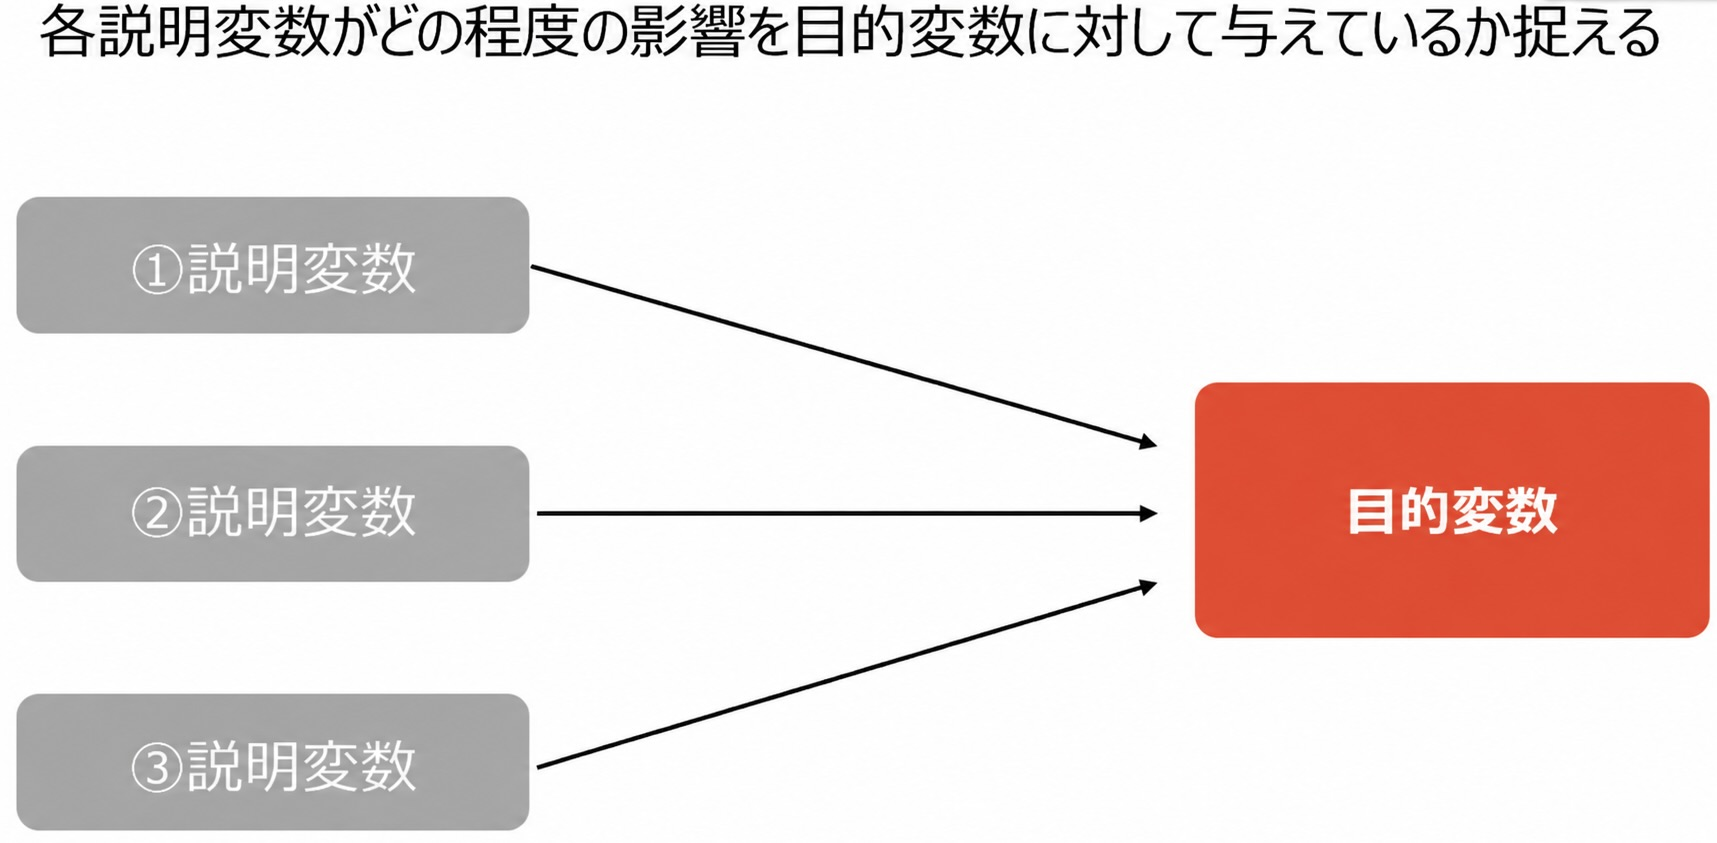

※図中の「影響」は、予測モデルで捉えられる**統計的な関係**を指します。回帰係数だけから因果関係を判断することはできません。また、説明変数の単位が異なる場合、係数の絶対値を単純に比較して重要度を判断することもできません。

### 2.1 自動車価格データの取り込み

それでは、実際にやってみましょう。ここでは、自動車の価格と属性（車体の大きさなど）のデータから、重回帰を使って価格を予測するモデルを構築します。

使用するのはUCI Machine Learning Repositoryの **Automobile** データセット（Schlimmer, 1985）[データセット1]です。コードでは講義用の配布先に置かれた `imports-85.data` を読み込みます。元データの出典とライセンスは末尾の「データ出典・ライセンス」を参照してください。


In [ ]:
# インポート
import requests, zipfile
import io

# 自動車価格データを取得
url = 'https://s3.ap-northeast-1.amazonaws.com/lecture-handouts.weblab/%E7%AC%AC6%E5%9B%9E/imports-85.data'

res = requests.get(url).content

# 取得したデータをDataFrameオブジェクトとして読み込み
auto = pd.read_csv(io.StringIO(res.decode('utf-8')), header=None)

# データの列にラベルを設定
auto.columns =['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors',
                            'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height',
                            'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore',
                            'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

上記のプログラムを実行すると、変数`auto`にPandasの`DataFrame`オブジェクトとして、自動車価格データが格納されます。
実際に、どのようなデータなのか確認してみましょう。

In [ ]:
print('自動車データの形式:{}'.format(auto.shape))

205行、26列のデータであることが分かります。

続いて次のように`head()`メソッドで、最初の5行を表示してみます。

In [ ]:
auto.head()

このデータにおいて、自動車の価格は`price`に設定されています。ここでは自動車の属性から価格を予測するモデルを作ろうとしているのですから、`price`以外の値から`price`を予測するモデルを作るというのが課題となります。

すべての説明変数から`price`を予測するのは複雑なので、この課題では、`horsepower`、`width`、`height`の3つの説明変数だけを使うものとします。つまり、`horsepower`、`width`、`height`という説明変数から`price`という目的変数を予測するというモデルを作成していくものとします。

### 2.2 データの整理

入力データには不適切なものが含まれていることがあります。そこでまずは、データの内容を確認して適切なデータとして整理します。

#### 欠損値の処理

先ほど`head()`で確認したデータには、欠損を表す文字列`'?'`が含まれています。ここで使用する`LinearRegression`は、そのような文字列を直接扱えないため、適切な前処理が必要です。なお、一般にカテゴリ変数は、削除せず数値に符号化して利用できる場合もあります。

今回は`horsepower`、`width`、`height`から`price`を予測するため、この4列を取り出し、`'?'`を欠損値に変換したうえで、その行を除外します。`'?'`が各列にいくつ含まれるかは、次のコードで確認できます。

In [ ]:
# モデル用に4列を取り出す（演習で使う元データ auto は保持する）
auto_model = auto[['price', 'horsepower', 'width', 'height']].copy()
# 各列に含まれる「?」の個数を数える
auto_model.isin(['?']).sum()

`price`と`horsepower`に'?'データが混入していることがわかるので、以前学んだPandasのテクニックを使って除外します。次のようにすると'?'がある行が除去されます。実行すると、行数が減っていることが確認できます。

In [ ]:
# 「?」をNaNに置換して、欠損値がある行を削除
auto_model = auto_model.replace('?', np.nan).dropna()
print('自動車データの形式:{}'.format(auto_model.shape))

#### 型の変換
ここでデータの型を確認しておきましょう。次のようにして確認します。

In [ ]:
print('データ型の確認（型変換前）\n{}\n'.format(auto_model.dtypes))

確認すると`price`と`horsepower`が数値型ではないことがわかります。そこで`to_numeric`を使って数値型に変換しておきます。

In [ ]:
auto_model = auto_model.assign(price=pd.to_numeric(auto_model.price))
auto_model = auto_model.assign(horsepower=pd.to_numeric(auto_model.horsepower))
print('データ型の確認（型変換後）\n{}'.format(auto_model.dtypes))

#### 相関の確認

以上の操作で、モデルに使う4列は欠損のない数値型データになりました。
続けて各変数の相関を確認します。次のように`corr()`を使うと、相関を確認できます。

In [ ]:
auto_model.corr()

`price`が今回の目的変数です。それ以外の3変数に注目すると、`width`と`horsepower`の相関係数は約0.62で、正の相関が見られます。このように説明変数どうしに強い線形関係があると、**多重共線性（multicollinearity）**が問題になる場合があります。

多重共線性が強いと、個々の回帰係数が不安定になり、その解釈が難しくなることがあります。ただし、相関係数がある程度高いという理由だけで、必ず変数を除外するわけではありません。予測と係数の解釈のどちらを重視するか、正則化を使うかなども踏まえて検討します。

本演習では、`width`、`horsepower`、`height`の3変数をそのまま使ってモデルを作ります。

### 2.3 モデル構築と評価

データが揃ったのでモデルを構築してみましょう。重回帰のモデルを作り、その性能を調べるプログラムは下記のようになります。

下記のプログラムでは、説明変数を$X$、目的変数を$y$に設定しています。

機械学習のモデル構築では、「モデル構築に使用する訓練データ」を使って学習させてモデルを構築し、そのモデルに訓練データとは別の「テストデータ」を入れて、そのテストデータに対して、どの程度の精度が得られるのかを確認することで性能を調べるのが一般的です。そこで以下では、Scikit-learnの`model_selection`モジュールの`train_test_split`関数を使い、訓練データとテストデータに分けています。

この関数はデータをランダムに2つに分ける関数です。どのような割合で分割するかは`test_size`で決めます。ここでは`test_size`を0.5にしているので半分ずつに分かれます（たとえば、0.4にすると4対6に分けることもできます）。

`random_state`は乱数のシード値を設定するものです。ここでは`random_state`を0に設定しています。このように`random_state`を固定すると、乱数に基づく分割を再現でき、同じデータに対して何度実行しても同じ分割が得られます。もし固定しないと、実行のたびに、ある行が訓練データに分類されたりテストデータに分類されたりとまちまちになるので、結果が一定となりません。ですから再現性を確保するために、`random_state`を固定することは重要です。


重回帰のモデル構築は、`LinearRegression`クラスを使って行います。「`model = LinearRegression()`」でインスタンスを作成して、訓練データを「`model.fit(X_train, y_train)`」のように読み込ませると学習が完了します。学習したら、決定係数や回帰係数、切片を確認できます。決定係数（$R^2$）は、予測が目的変数の変動をどの程度捉えているかを示す指標です。1に近いほど良い値ですが、テストデータでは負になることもあります。

機械学習の目的は高い汎化性能の獲得（構築したモデルによって、未知データでも適切に予測できること）ですから、訓練データへのあてはまりを追求すれば良いモデルになりそうですが、実際はそうではなく、訓練データに対する精度は良いがテストデータに対する精度が低くなるということがしばしば起きます。このことを**過学習（overfitting）**もしくは**過剰学習**と呼び、モデル構築の段階において過学習になっていないかを検証します。過学習への対処は、第4節以降でも扱います。

最小二乗法による重回帰の目的関数は、$y$を実測値、$ f(\textbf{x}) = w_1x_1 + w_2x_2 + w_3x_3 +\cdots + b $を予測値として、以下の式のように表されます。この式を最小化するような係数を求めます。

\begin{eqnarray}
\sum^n_{i=1}(y_i-f(\textbf{x}_i))^2
\end{eqnarray}

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 説明変数と目的変数
X = auto_model[['horsepower', 'width', 'height']]
y = auto_model['price']

# 訓練データとテストデータに半分ずつ分割
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=0
)

# モデルの学習
model = LinearRegression()
model.fit(X_train, y_train)

# 決定係数（R^2）による評価
print('決定係数(train):{:.3f}'.format(model.score(X_train, y_train)))
print('決定係数(test):{:.3f}'.format(model.score(X_test, y_test)))
print('切片:{:.3f}'.format(model.intercept_))
print('回帰係数:', dict(zip(X.columns, model.coef_)))

`test_size`を変更すると、訓練データとテストデータの構成が変わるため、決定係数も変化する場合があります。変更した場合はモデルを再学習し、結果を確認してください。

決定係数は`score`メソッドで取得できます。訓練データとテストデータの決定係数を比べ、訓練データでの当てはまりが良い一方、テストデータでは悪くなっていないかを確認しましょう。ただし、単一の分割結果だけで過学習の有無を断定することはできません。

### 2.4 モデル構築とモデル評価の流れのまとめ

以上が重回帰によるモデル構築と評価の流れです。ロジスティック回帰や決定木でも、データの分割、学習、評価という基本的な流れは共通しています。

- 説明変数と目的変数を設定する：$X$と$y$
- 訓練データとテストデータに分ける：`train_test_split(X, y, test_size=0.5, random_state=0)`
- モデルを初期化する：`model = LinearRegression()`
- 訓練データで学習する：`model.fit(X_train, y_train)`
- テストデータで評価する：`model.score(X_test, y_test)`

`score`が返す指標はモデルの種類によって異なります。ここで使う`LinearRegression`は決定係数（$R^2$）、後述の分類モデルは正解率を返します。

ここでは、モデル構築の際、使用する説明変数として`horsepower`、`width`、`height`の3つを恣意的に選択しましたが、統計的に選択する方法もいくつかあります。具体的には、**変数増加法（前進的選択法）**、**変数減少法（後退的選択法）**、**ステップワイズ法**などで、選択するための規準も、RMSE（Root Mean Squared Error）、赤池情報量規準（AIC）、ベイズ情報量規準（BIC）などがあります。これらも絶対的にこの方法が有効というものではなく、モデルの汎化性能であったりビジネスドメイン知識なども考慮され選択されます。上記方法についての詳細は本書では割愛しますので、汎化性能を比較して変数を選ぶ場合、最終評価用のテストデータを使い回さず、交差検証などを用いることが重要です。詳しくは必要に応じて調べてみてください。

>**[やってみよう]**
>
>変数増加法、変数減少法、ステップワイズ法について調べてみましょう。

#### <練習問題 1>

第2節で読み込んだ**元の自動車価格データ`auto`**を使います。`price`を目的変数、`length`と`engine-size`を説明変数として、重回帰モデルを構築してください。

必要な3列を取り出し、`'?'`などの欠損を処理したうえで、数値型に変換してください。`train_test_split(test_size=0.5, random_state=0)`で訓練・テストデータに分け、テストデータの決定係数（$R^2$）を求めましょう。

In [ ]:
# <練習問題 1>
# WRITE ME

#### <練習問題 2>

同じ元データ`auto`から、練習問題1とは異なる説明変数を選んで`price`を予測してください。必要な欠損処理と型変換を行い、`train_test_split(test_size=0.5, random_state=0)`で分割して、テストデータの決定係数（$R^2$）を求めます。

選んだ説明変数によって結果がどう変わったか、その理由も考えてみましょう。

※2つのモデルの性能を公平に比較するには、評価に用いるデータの行と分割条件を揃えることも重要です。

In [ ]:
#<練習問題 2>
# WRITE ME

## 3 ロジスティック回帰
キーワード：ロジスティック回帰、分類、交差エントロピー誤差関数、標準化

重回帰は、連続的な数値を予測する回帰モデルです。

一方、本節で学ぶ**ロジスティック回帰（logistic regression）**は、例えば商品を購入するかどうかや企業が倒産するかどうかなど、カテゴリを予測するために使われます。このようなカテゴリの情報を表す変数を**カテゴリ変数**といいます。カテゴリは、モデルに入力する際に0や1などの数値で表現することもあります。

分類（classification）は、入力データをいずれかのクラスに割り当てるタスクです。ロジスティック回帰では、各クラスに属する確率を推定し、それに基づいて分類を行います。

「回帰」という名前ですが、主な用途は分類です。2クラスだけでなく多クラス分類にも対応できます。ここでは**二値分類**の場合を考え、基本となる損失関数として次の**交差エントロピー損失（cross-entropy loss）**を示します。$y_i$は正解ラベル（0または1）、$f(\mathbf{x}_i)$はクラス1に属する予測確率です。正解クラスへの予測確率が高いほど、損失は小さくなります。

なお、後述する`LogisticRegression`の標準設定では、この損失に加えて**L2正則化**の影響も含めてパラメータを推定します。

\begin{eqnarray}
-\sum^n_{i=1}[y_ilog(f(x_i))+(1-y_i)log(1-f(x_i))]
\end{eqnarray}

### 3.1 ロジスティック回帰の例

それでは具体的にロジスティック回帰の例を見ていきましょう。ここでは、年齢や職業などを含むUCI Machine Learning Repositoryの **Adult** データセット（Becker & Kohavi, 1996）[データセット2]から、収入が50K（5万ドル）を超えるかどうかを予測します。ただし、本演習で実際に説明変数として使うのは、後述する5つの数値変数です。

まずは次のようにデータを取得し、カラム名を設定します。ここでは講義用の配布先から **`adult.data`（32,561行、15列）** を読み込みます。UCIのデータセット全体は48,842件ですが、本演習は別ファイルの `adult.test` を読み込まず、`adult.data` の中で訓練・テスト分割を行います。

`isnull()`では欠損値は検出されませんが、このデータでは一部のカテゴリ変数に不明値を表す`?`が含まれています。本教材でモデルに使う5つの数値変数には、この`?`は含まれません。`head()`で先頭を見ると、`workclass`や`education`などのカテゴリ変数と、`age`や`education-num`などの数値変数が混在していることがわかります。

元データの出典とライセンスは末尾の「データ出典・ライセンス」を参照してください。


In [ ]:
# データを取得
url = 'https://s3.ap-northeast-1.amazonaws.com/lecture-handouts.weblab/%E7%AC%AC6%E5%9B%9E/adult.data'
res = requests.get(url).content

# 取得したデータをDataFrameオブジェクトとして読み込み
adult = pd.read_csv(io.StringIO(res.decode('utf-8')), header=None)

# データの列にラベルを設定
adult.columns =['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
                             'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week',
                             'native-country', 'flg-50K']


# データの形式と欠損数を出力
print('データの形式:{}'.format(adult.shape))
print('欠損の数:{}'.format(adult.isnull().sum().sum()))

# データの先頭5行を出力
adult.head()

### 3.2 データの整理

このデータセットにおいて、収入が50Kを超えるかどうかを示す目的変数は`flg-50K`です。データの値は「`<=50K`」と「`>50K`」で、このままでは扱いにくいので、0または1のフラグが入った変数に変換します。まずは、「`<=50K`」と「`>50K`」の行が、それぞれいくつあるかを確認してみます。

In [ ]:
adult.groupby('flg-50K').size()

「`<=50K`」が24,720行、「`>50K`」が7,841行であることが分かります。

次に、`fin_flg`という列を追加して、「`>50K`」である行には1、それ以外は0とフラグ立てをします。フラグ立てには`lambda`や`map`を使います。変換したら、念のため上の集計結果と同じであることをチェックします。

In [ ]:
# 「fin_flg」カラムを追加し、もし「flg-50K」カラムの値が「>50K」だったら1、そうでなければ0をセットする
adult['fin_flg'] = adult['flg-50K'].map(lambda x: 1 if x == ' >50K' else 0)
adult.groupby('fin_flg').size()

「`<=50K`」と「`>50K`」の行数が、「0」と「1」の行数と一致したのでうまくいったことが分かります。

### 3.3 モデル構築と評価
いよいよロジスティック回帰のモデル構築です。説明変数として、数値変数の`age`、`fnlwgt`、`education-num`、`capital-gain`、`capital-loss`を使うことにします。目的変数は、先ほど「1」と「0」のフラグを立てた`fin_flg`です。

ロジスティック回帰のモデル構築には`LogisticRegression`クラスを使います。訓練データとテストデータに分けたり、`score`メソッドで評価したりする方法は、重回帰のときと同じです。

※`fnlwgt`はAdultデータに含まれる人口集計上の重みです。本演習では数値変数の一つとして使いますが、実務では予測時に利用可能な特徴量かどうかも検討する必要があります。

特徴量のスケールが大きく異なると、ロジスティック回帰の最適化計算が収束しにくくなり、`ConvergenceWarning`が表示されることがあります。

次のセルでは計算回数の上限を増やしてモデルを学習します。その後、3.4では標準化を行い、スケールを揃えた場合と比較します。

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 説明変数と目的変数の設定
X = adult[['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss']]
y = adult['fin_flg']

# 訓練データとテストデータに分ける
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# ロジスティック回帰クラスの初期化と学習
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print('正解率(train):{:.3f}'.format(model.score(X_train, y_train)))
print('正解率(test):{:.3f}'.format(model.score(X_test, y_test)))

訓練データとテストデータの正解率を比較します。訓練データでの正解率だけが高い場合は、過学習を疑う手がかりになります。

このデータでは年収が50K以下の人が約76%を占めるため、多数派のクラスだけを予測しても約76%の正解率になります。そのため、正解率だけで性能を判断せず、必要に応じて適合率・再現率・F1スコアなども確認しましょう。実務でモデルやパラメータを選ぶ際は、最終テストデータとは別の検証データや交差検証を使います。

### 3.4 スケーリング

ここで**標準化（standardization）**を扱います。今回の5つの説明変数は単位や値の大きさが大きく異なります。標準化では、各値から訓練データの平均を引き、訓練データの標準偏差で割ることで、変数のスケールを揃えます。

スケールを揃えることは、ロジスティック回帰の最適化計算を安定させたり、正則化が各特徴量に与える影響を比較しやすくしたりするうえで重要です。標準化には`StandardScaler`クラスを使います。

In [ ]:
# 標準化のためのクラスをインポート
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Xとyを設定
X = adult[['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss']]
y = adult['fin_flg']

# 訓練データとテストデータに分ける
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# 標準化処理
sc = StandardScaler()
sc.fit(X_train)
X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)

# ロジスティック回帰クラスの初期化と学習
model = LogisticRegression(max_iter=1000)
model.fit(X_train_std, y_train)

# 正解率の表示
print('正解率(train):{:.3f}'.format(model.score(X_train_std, y_train)))
print('正解率(test):{:.3f}'.format(model.score(X_test_std, y_test)))

標準化前後の正解率を比較してみましょう。データによっては正解率の差が小さい場合もありますが、スケールを揃えることで最適化が安定しやすくなります。

ここで重要なのは、`StandardScaler`を**訓練データだけで`fit`している**点です。テストデータは未知データの代わりなので、テストデータの平均や標準偏差を学習時に利用してはいけません。テストデータには、訓練データから求めた変換を`transform`だけします。

#### <練習問題 3>

`sklearn.datasets`モジュールの`load_breast_cancer`関数を使って、**Breast Cancer Wisconsin (Diagnostic)** [データセット3]を読み込み、目的変数を`cancer.target`、説明変数を`cancer.data`としてロジスティック回帰で予測モデルを構築してください。このとき、`train_test_split(test_size=0.3, random_state=0)`で訓練データとテストデータに分け、テストデータで正解率を求めてください。

※このデータセットは乳房腫瘤の穿刺吸引細胞診（FNA）の画像から計算した数値特徴量のデータであり、画像そのものを説明変数として扱う演習ではありません。出典は解答のNotebookの末尾に記載しています。


In [ ]:
#<練習問題 3>
# WRITE ME

####  <練習問題 4>
<練習問題 3>と同じデータと分割条件を使い、訓練データで求めた平均・標準偏差を使って特徴量を標準化し、モデルを構築してください。そのうえで、練習問題3の結果と比較してください。

In [ ]:
#<練習問題 4>
# WRITE ME

## 4 過学習と正則化
キーワード：過学習、正則化、リッジ回帰、ラッソ回帰

ここまで、訓練データとテストデータを分けて評価する理由として**過学習**を扱いました。モデルを複雑にすると訓練データにはよく当てはまりやすくなりますが、複雑すぎるモデルは未知のデータに対する性能が下がることがあります。

そこで、モデルを必要以上に複雑にしないように制約を加える考え方を**正則化（regularization）**といいます。

### 4.1 正則化の考え方

正則化では、単に予測誤差を小さくするだけでなく、モデルが複雑になりすぎることにもペナルティを与えます。考え方を大まかに書くと、次のようになります。

> **学習で小さくしたい値 = 予測誤差 + モデルの複雑さに対するペナルティ**

線形モデルでは、係数を極端に大きくしないようにすることで、モデルの複雑さを抑えます。ペナルティの強さを調整するパラメータもあり、強くしすぎると逆に十分に学習できなくなるため、適切なバランスが重要です。

### 4.2 RidgeとLasso

線形回帰で代表的な正則化手法が**リッジ回帰（Ridge）**と**ラッソ回帰（Lasso）**です。

| 手法 | 正則化 | 主な特徴 |
|---|---|---|
| Ridge | L2正則化 | 係数を全体的に小さくする |
| Lasso | L1正則化 | 一部の係数を0にできることがある |

Scikit-learnでは、`Ridge`、`Lasso`クラスで利用できます。また、前節で使った`LogisticRegression`にも、標準設定ではL2正則化が含まれます。第3節の交差エントロピー損失の説明は、その基本となる損失項を示したものです。

この回では、Ridge/Lassoの実装方法や数式の詳細よりも、**「過学習を抑えるためにモデルの複雑さへ制約を加える」という正則化の考え方**を押さえてください。

> **[発展・調べてみよう]**
>
> `sklearn.linear_model.Ridge` と `sklearn.linear_model.Lasso` の公式ドキュメントを確認し、`alpha`パラメータが何を調整するのか調べてみましょう。余裕があれば、第2節の自動車価格データで通常の線形回帰と結果を比較してみてください。
>
>*   [sklearn.linear_model.Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
>*   [sklearn.linear_model.Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)




## 5 決定木
キーワード：決定木、不純度、ジニ不純度、エントロピー、情報利得

**決定木（Decision Tree）**は、データの特徴量に対して「この値以下か？」のような条件分岐を繰り返し、最終的な予測を行うモデルです。目的変数がカテゴリなら**分類木**、数値なら**回帰木**と呼びます。

この節では、ロジスティック回帰で利用した**Adultデータ**をそのまま使います。同じ分類問題に異なるモデルを適用することで、モデルによる考え方の違いを確認します。

### 5.1 決定木はどのように分岐するか

決定木では、分岐後のグループができるだけ同じクラスにまとまるような条件を探します。この「クラスの混ざり具合」を**不純度（impurity）**と呼びます。

代表的な不純度の指標には、**ジニ不純度（Gini impurity）**や**エントロピー（entropy）**があります。分岐後のグループの不純度を、データ数に応じて重み付けした平均が小さくなるように分岐を選びます。エントロピーを使う場合、分岐によってどれだけ不純度が減ったかを**情報利得（information gain）**と呼びます。

この回では数式を手計算することよりも、**「よりクラスを分けやすい条件をモデルが探して木を作る」**という考え方を押さえましょう。Scikit-learnの`DecisionTreeClassifier`は、標準設定ではジニ不純度を使います。

### 5.2 Adultデータで決定木を作る

ロジスティック回帰と同じ5つの数値変数を説明変数にし、収入が50Kを超えるかどうかを予測します。第3.3節の標準化前のロジスティック回帰と同じ`random_state=0`、`test_size=0.3`で分割し、同じ条件でモデルを比較します。

決定木は特徴量の値の大小によって分岐するため、**標準化は基本的に必要ありません**。

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# ロジスティック回帰と同じ説明変数・目的変数を利用
X = adult[['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss']]
y = adult['fin_flg']

# 同じ条件で訓練データとテストデータに分ける
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

# 決定木モデルを構築
model = DecisionTreeClassifier(max_depth=4, random_state=0)
model.fit(X_train, y_train)

print('正解率(train):{:.3f}'.format(model.score(X_train, y_train)))
print('正解率(test):{:.3f}'.format(model.score(X_test, y_test)))

ロジスティック回帰と決定木で、訓練データ・テストデータの正解率を比較してみましょう。モデルが違えば、同じデータを使っても結果は変わります。

また、決定木では`max_depth`で木の深さを制限できます。深い木ほど複雑な条件分岐を表現できますが、訓練データに合わせすぎると過学習につながります。

### 5.3 木の深さと過学習

`max_depth`を変え、訓練データとテストデータの正解率がどう変化するかを学習目的で確認します。ただし、最終的に採用する深さを決めるときは、テストデータではなく検証データや交差検証を使います。ここでは**正則化と同じく「モデルを複雑にしすぎない」ことが重要**だと捉えてください。

In [ ]:
depths = [2, 4, 6, None]

for depth in depths:
    tree_model = DecisionTreeClassifier(max_depth=depth, random_state=0)
    tree_model.fit(X_train, y_train)
    print(
        'max_depth={}: train={:.3f}, test={:.3f}'.format(
            depth,
            tree_model.score(X_train, y_train),
            tree_model.score(X_test, y_test)
        )
    )

一般に木を深くすると訓練データの正解率は高くなりやすい一方、テストデータの正解率まで常に高くなるとは限りません。訓練データとテストデータの両方を見ることで、過学習していないかを確認します。

### 5.4 決定木を可視化する

決定木は条件分岐を図として確認できるため、モデルがどのようなルールを作ったかを比較的理解しやすい特徴があります。scikit-learnの`plot_tree`を使えば、追加パッケージなしで簡単に可視化できます。下のコードは深さ4の木を学習し、図では深さ2までを表示します。

（下図出典：Becker, B., & Kohavi, R. "Adult", UCI Machine Learning Repository (1996) のデータを基に、scikit-learnで作図。[Licensed under CC BY 4.0]）


In [ ]:
from sklearn.tree import plot_tree

# 見やすいよう、深さ4のモデルを改めて作成
model = DecisionTreeClassifier(max_depth=4, random_state=0)
model.fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=['<=50K', '>50K'],
    filled=True,
    max_depth=2,  # 可視化する深さのみを制限（学習モデルは深さ4）
    fontsize=9
)
plt.show()

図では、上から順にどの特徴量・しきい値でデータを分けているかを追えます。すべての枝を暗記する必要はありません。**条件分岐の積み重ねで予測していること**、そして**木を深くするとモデルが複雑になること**を確認してください。

#### <練習問題 5>

`sklearn.datasets`モジュールの`load_breast_cancer`関数から乳がんデータを読み込み、目的変数を`cancer.target`、説明変数を`cancer.data`として決定木モデルを構築してください。

1. `max_depth=2`, `4`, `None`を試し、訓練スコアとテストスコアを比較してください。  
2. どの設定で過学習が起きていそうか考えてください。  
3. 余裕があれば`criterion='entropy'`も試し、標準設定の`gini`と比較してください。

In [ ]:
# <練習問題 5>
# WRITE ME

## 6 その他の教師あり学習（発展・自習）

教師あり学習には、本編で扱ったモデル以外にも多くの手法があります。必要になったときに、特徴と使い方を調べられるようにしておきましょう。

- **k-NN（k近傍法）**：近くにあるデータを参考にして予測する。距離を使うため、特徴量のスケールの影響を受けやすい。`KNeighborsClassifier` / `KNeighborsRegressor`
- **SVM（サポートベクターマシン）**：分類ではクラス間の境界を考える手法。回帰に使う型もある。特徴量のスケーリングが重要になることが多い。`SVC` / `SVR`
- **ランダムフォレスト**：複数の決定木を組み合わせて予測する
- **勾配ブースティング**：モデルを順番に組み合わせて予測性能を高める

> **[調べてみよう]**  
> k-NNとSVMについて、①どのような考え方のモデルか、②標準化がなぜ重要になりやすいか、③Scikit-learnではどのクラスを使うかを公式ドキュメントで確認してみましょう。

## 7 総合問題

### ■ 総合問題 1 教師あり学習の用語

次の用語について、それぞれの役割や意味を自分の言葉で説明してください。

- 教師あり学習
- 回帰 / 分類
- 説明変数 / 目的変数
- 訓練データ / テストデータ
- 過学習 / 汎化性能
- 重回帰
- ロジスティック回帰
- 標準化
- 正則化
- Ridge / Lasso
- 決定木
- 不純度

**発展**：エントロピー、情報利得、k-NN、SVMについても調べてみましょう。

In [ ]:
# <総合問題 1 教師あり学習の用語>
# WRITE ME

### ■ 総合問題 2 決定木

練習問題で利用した乳がんデータについて、決定木を使って予測と評価を行ってください。`max_depth`を複数試し、訓練データとテストデータのスコアから、モデルの複雑さと過学習の関係を考察してください。

In [ ]:
# <総合問題 2 決定木>
# WRITE ME

### ■ 総合問題 3 モデルを比較する

同じ分類データに対して、ロジスティック回帰と決定木を適用し、テストデータの結果を比較してみましょう。

モデルによって得意・不得意があり、**どの問題でも必ず最良になる単一の学習アルゴリズムがあるわけではありません**。この実務上の考え方は、機械学習で知られる「ノーフリーランチ」の議論とも関連しています。ただし、定理の厳密な主張とは区別し、ここでは「データや目的に応じてモデルを比較・評価することが重要」と理解してください。

In [ ]:
# <総合問題 3 モデルを比較する>
# WRITE ME

## 使用データセット・参考文献について

　本教材では、UCI Machine Learning Repositoryで公開されている以下の外部データセットを使用しています。

　また、データセットに関連する研究論文を参考文献として記載しています。 （出典・ライセンス情報の最終確認日：2026年10月31日）


[データセット1] **Automobile**（第2章：重回帰）  
   Schlimmer, J. (1985). *Automobile* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5B01C  
   UCI公式ページ：https://archive.ics.uci.edu/dataset/10/automobile  
   元データは1985年のWard's Automotive Yearbookに由来します。講義では `imports-85.data` を用います。

[データセット2] **Adult**（第3章：ロジスティック回帰、第5章：決定木）  
   Becker, B., & Kohavi, R. (1996). *Adult* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20  
   UCI公式ページ：https://archive.ics.uci.edu/dataset/2/adult  
   本ノートブックでは、データセット全体48,842件のうち `adult.data` の32,561件を利用します（`adult.test`は使用しません）。

[データセット3] **Breast Cancer Wisconsin (Diagnostic)**（練習問題3〜5・総合問題）  
   Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B  
   UCI公式ページ：https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic  
   このデータはscikit-learnの [`load_breast_cancer()`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) に収録されています。UCIの *Breast Cancer Wisconsin (Original)* とは異なるデータセットです。


**ライセンスおよび利用に関する注記**

[データセット1][データセット2][データセット3]のデータセットはCreative Commons Attribution 4.0 International（CC BY 4.0）ライセンスの下で公開されています。

- ライセンス詳細：https://creativecommons.org/licenses/by/4.0/


**関連論文・参考文献**

[参考文献]
- 塚本邦尊、山田典一、大澤文孝『東京大学のデータサイエンティスト育成講座』（マイナビ出版、2019年）
